# How Does Neural Noise Limit Visual Discrimination?
### Computational neuroscience project

**Goal:** simulate orientation-selective neurons, noisy spike counts, population decoding, and shared noise.

This is a simplified teaching model, not biological data. Run cells from top to bottom. The notebook includes explanations, comments, plots, and a limitations section.

## 1. Imports and reproducibility
NumPy handles arrays and random simulations; Matplotlib makes plots; SciPy provides Poisson probabilities.

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson
import pandas as pd

# Fix the random seed so results are reproducible when cells run in order.
np.random.seed(42)
print("Ready to simulate neural responses.")

Ready to simulate neural responses.


## 2. Orientation tuning curve

A neuron responds most strongly to its preferred orientation. We use a Gaussian-shaped tuning curve:

\[
r(\theta)=r_{base}+A\exp\left[-\frac{(\theta-\theta_{pref})^2}{2\sigma_\theta^2}\right]
\]

Here, theta is stimulus orientation, theta_pref is preferred orientation, r_base is baseline rate, A is peak increase, and sigma_theta controls tuning width. The curve describes the **mean** firing rate, not each individual trial.

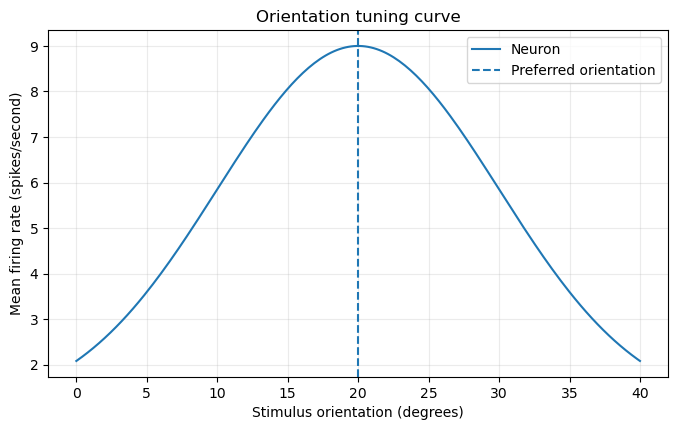

Peak rate: 9.0 spikes/second


In [38]:
# Parameters for one orientation-selective neuron
r_base = 1.0          # baseline firing rate (spikes/second)
A = 8.0               # peak increase above baseline (spikes/second)
sigma_theta = 10.0    # tuning width (degrees)
theta_pref = 20.0     # preferred orientation (degrees)

theta_values = np.linspace(0, 40, 200)

def tuning_rate(theta, preferred=theta_pref):
    """Mean firing rate (spikes/second) for a stimulus orientation."""
    return r_base + A * np.exp(
        -((theta - preferred)**2) / (2 * sigma_theta**2)
    )

plt.figure(figsize=(8, 4.5))
plt.plot(theta_values, tuning_rate(theta_values), label="Neuron")
plt.axvline(theta_pref, linestyle="--", label="Preferred orientation")
plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/second)")
plt.title("Orientation tuning curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Peak rate:", tuning_rate(theta_pref), "spikes/second")

At the preferred orientation the exponent is zero, so the peak rate is r_base + A = 9 spikes/second. Changing theta_pref shifts the peak horizontally without changing its height.

## 3. Convert firing rate to expected spike count

For a presentation lasting T seconds:

\[
\lambda(\theta)=r(\theta)T
\]

Lambda is the expected number of spikes across repeated presentations. It does not need to be an integer.

In [39]:
duration = 0.2  # presentation duration in seconds
lambda_at_preferred = tuning_rate(theta_pref) * duration
print(f"Expected count at preferred orientation: {lambda_at_preferred:.2f}")

Expected count at preferred orientation: 1.80


## 4. Simulate Poisson neural noise

We model the observed count as N|theta ~ Poisson(lambda(theta)). For a Poisson variable, mean = variance = lambda, and standard deviation = sqrt(lambda). Repeated presentations of the same stimulus can produce different counts.

Theoretical mean: 1.800
Observed mean:    1.771
Theoretical var:  1.800
Observed var:     1.833
Observed SD:      1.354


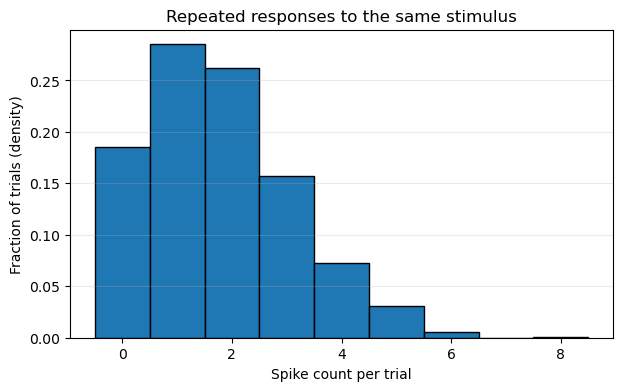

In [40]:
lam = lambda_at_preferred
n_repeats = 1000

# Each draw is one repeated presentation of the same stimulus.
spike_counts = np.random.poisson(lam, size=n_repeats)

print(f"Theoretical mean: {lam:.3f}")
print(f"Observed mean:    {np.mean(spike_counts):.3f}")
print(f"Theoretical var:  {lam:.3f}")
print(f"Observed var:     {np.var(spike_counts):.3f}")
print(f"Observed SD:      {np.std(spike_counts):.3f}")

bins = np.arange(-0.5, max(spike_counts) + 1.5, 1)
plt.figure(figsize=(7, 4))
plt.hist(spike_counts, bins=bins, density=True, edgecolor="black")
plt.xlabel("Spike count per trial")
plt.ylabel("Fraction of trials (density)")
plt.title("Repeated responses to the same stimulus")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 5. One neuron: distinguish 20° from 25°?

We calculate the expected counts for two nearby orientations, simulate many trials, and visualize how much their response distributions overlap.

Expected count at 20 degrees: 1.800
Expected count at 25 degrees: 1.612


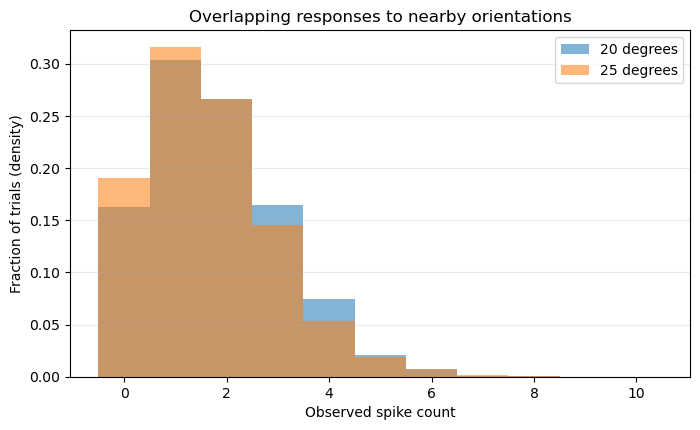

In [41]:
def expected_count_single(theta):
    return tuning_rate(theta) * duration

lambda_20_single = expected_count_single(20)
lambda_25_single = expected_count_single(25)

print(f"Expected count at 20 degrees: {lambda_20_single:.3f}")
print(f"Expected count at 25 degrees: {lambda_25_single:.3f}")

n_trials = 5000
counts_20_single = np.random.poisson(lambda_20_single, size=n_trials)
counts_25_single = np.random.poisson(lambda_25_single, size=n_trials)

bins = np.arange(-0.5, 11.5, 1)
plt.figure(figsize=(8, 4.5))
plt.hist(counts_20_single, bins=bins, density=True, alpha=0.55, label="20 degrees")
plt.hist(counts_25_single, bins=bins, density=True, alpha=0.55, label="25 degrees")
plt.xlabel("Observed spike count")
plt.ylabel("Fraction of trials (density)")
plt.title("Overlapping responses to nearby orientations")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.show()

## 6. Maximum-likelihood decoder for one neuron

For a Poisson neuron:

\[
P(N=k\mid\theta)=\frac{e^{-\lambda(\theta)}\lambda(\theta)^k}{k!}
\]

Maximum likelihood (ML) chooses the candidate stimulus that makes the observed count most probable.

In [42]:
def decode_single_ml(observed_count):
    # Compare the probability of this count under each candidate orientation.
    p20 = poisson.pmf(observed_count, lambda_20_single)
    p25 = poisson.pmf(observed_count, lambda_25_single)
    return 20.0 if p20 >= p25 else 25.0

example_count = 2
print("P(count=2 | 20 degrees):", poisson.pmf(example_count, lambda_20_single))
print("P(count=2 | 25 degrees):", poisson.pmf(example_count, lambda_25_single))
print("Decoded orientation:", decode_single_ml(example_count))

# Evaluate on many trials; average class-specific accuracies for balanced accuracy.
pred20 = np.array([decode_single_ml(n) for n in counts_20_single])
pred25 = np.array([decode_single_ml(n) for n in counts_25_single])
accuracy_single = (np.mean(pred20 == 20) + np.mean(pred25 == 25)) / 2
print(f"Single-neuron balanced accuracy: {accuracy_single:.3f}")

P(count=2 | 20 degrees): 0.26778419891897026
P(count=2 | 25 degrees): 0.25918917324842156
Decoded orientation: 20.0
Single-neuron balanced accuracy: 0.520


## 7. Build a population of neurons

We use neurons with different preferred orientations. Each neuron has its own tuning curve, and together their responses form a population code.

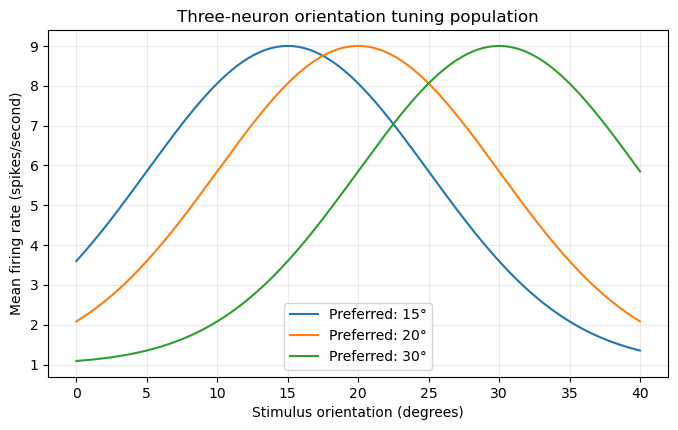

Expected counts at 20 degrees: [1.612 1.8   1.17 ]
Expected counts at 25 degrees: [1.17  1.612 1.612]


In [43]:
preferred_orientations = np.array([15.0, 20.0, 30.0])

def population_expected_counts(theta, preferences=preferred_orientations):
    # Calculate one expected count for each neuron's preferred orientation.
    rates = r_base + A * np.exp(
        -((theta - preferences)**2) / (2 * sigma_theta**2)
    )
    return rates * duration

plt.figure(figsize=(8, 4.5))
for pref in preferred_orientations:
    curve = r_base + A * np.exp(
        -((theta_values - pref)**2) / (2 * sigma_theta**2)
    )
    plt.plot(theta_values, curve, label=f"Preferred: {pref:.0f}°")
plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/second)")
plt.title("Three-neuron orientation tuning population")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

pop_lambda_20 = population_expected_counts(20)
pop_lambda_25 = population_expected_counts(25)
print("Expected counts at 20 degrees:", np.round(pop_lambda_20, 3))
print("Expected counts at 25 degrees:", np.round(pop_lambda_25, 3))

Each row of the next arrays is one trial; each column is one neuron. For example, [2, 1, 3] means the three neurons emitted 2, 1, and 3 spikes on that trial.

In [44]:
n_trials_population = 5000

# Independent Poisson sampling for each neuron and each trial.
population_20_ind = np.random.poisson(
    pop_lambda_20, size=(n_trials_population, len(preferred_orientations))
)
population_25_ind = np.random.poisson(
    pop_lambda_25, size=(n_trials_population, len(preferred_orientations))
)
print("First five population responses to 20 degrees:")
print(population_20_ind[:5])

First five population responses to 20 degrees:
[[1 1 2]
 [1 1 1]
 [3 2 4]
 [0 3 2]
 [3 0 0]]


## 8. Population maximum-likelihood decoding

If responses are conditionally independent given the stimulus, the joint likelihood factorizes:

\[
P(N_1,\ldots,N_m\mid\theta)=\prod_i P(N_i\mid\theta)
\]

We add log probabilities instead of multiplying tiny probabilities. This decoder is valid for the independent Poisson model.

In [45]:
def decode_population_independent_ml(response):
    logp20 = np.sum(poisson.logpmf(response, pop_lambda_20))
    logp25 = np.sum(poisson.logpmf(response, pop_lambda_25))
    return 20.0 if logp20 >= logp25 else 25.0

pred20 = np.array([decode_population_independent_ml(row) for row in population_20_ind])
pred25 = np.array([decode_population_independent_ml(row) for row in population_25_ind])
accuracy_population_ind = (np.mean(pred20 == 20) + np.mean(pred25 == 25)) / 2

print(f"Single-neuron balanced accuracy: {accuracy_single:.3f}")
print(f"Three-neuron independent population accuracy: {accuracy_population_ind:.3f}")

Single-neuron balanced accuracy: 0.520
Three-neuron independent population accuracy: 0.604


## 9. Add shared fluctuations to create correlated noise

We introduce one positive gain fluctuation per trial, shared by all neurons:

\[
g_t=\exp(\sigma_s z_t-\sigma_s^2/2),\quad z_t\sim\mathcal{N}(0,1)
\]

Each neuron's Poisson rate is multiplied by this gain. The gain has theoretical mean 1, so average rates remain comparable. Conditional on the shared gain, Poisson draws are independent; after averaging over the shared gain, the neuron responses become statistically dependent.

In [46]:
def simulate_shared_gain_population(theta, n_trials, sigma_shared=0.5):
    base_lam = population_expected_counts(theta)

    # Draw one shared latent fluctuation for each trial.
    z = np.random.normal(0, 1, size=n_trials)

    # Exponentiation keeps gain positive; correction gives mean gain = 1.
    gain = np.exp(sigma_shared * z - sigma_shared**2 / 2)

    # The same trial-specific gain affects every neuron.
    trial_lambdas = gain[:, None] * base_lam[None, :]

    # Generate integer, nonnegative spike counts.
    return np.random.poisson(trial_lambdas)

sigma_shared = 0.5
population_20_shared = simulate_shared_gain_population(20, n_trials_population, sigma_shared)
population_25_shared = simulate_shared_gain_population(25, n_trials_population, sigma_shared)

print("First five shared-gain responses:")
print(population_20_shared[:5])

First five shared-gain responses:
[[3 5 1]
 [2 0 3]
 [2 2 1]
 [0 1 0]
 [1 0 0]]


### Inspect response correlations

Off-diagonal entries show correlations between different neurons across trials. Diagonal entries are 1 because each neuron is perfectly correlated with itself.

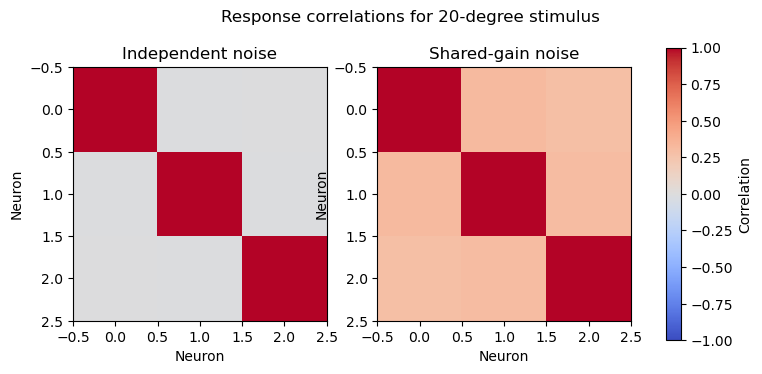

Independent correlation matrix:
 [[ 1.   -0.01 -0.01]
 [-0.01  1.   -0.01]
 [-0.01 -0.01  1.  ]]
Shared-gain correlation matrix:
 [[1.   0.31 0.28]
 [0.31 1.   0.3 ]
 [0.28 0.3  1.  ]]


In [47]:
corr_ind = np.corrcoef(population_20_ind.T)
corr_shared = np.corrcoef(population_20_shared.T)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
im = axes[0].imshow(corr_ind, vmin=-1, vmax=1, cmap="coolwarm")
axes[0].set_title("Independent noise")
axes[1].imshow(corr_shared, vmin=-1, vmax=1, cmap="coolwarm")
axes[1].set_title("Shared-gain noise")
for ax in axes:
    ax.set_xlabel("Neuron")
    ax.set_ylabel("Neuron")
fig.colorbar(im, ax=axes, label="Correlation")
plt.suptitle("Response correlations for 20-degree stimulus")
plt.show()

print("Independent correlation matrix:\n", np.round(corr_ind, 2))
print("Shared-gain correlation matrix:\n", np.round(corr_shared, 2))

## 10. Compare decoding in the two noise conditions

Important: the independent Poisson product likelihood is **not** a valid joint likelihood for the shared-gain population. Shared gain makes responses dependent.

For a transparent first comparison, use the same simple nearest-mean decoder in both conditions. It chooses whichever expected population count vector is closer in squared Euclidean distance. This is not guaranteed to be optimal, so the comparison is illustrative rather than a universal claim that correlations always reduce accuracy.

In [48]:
def make_nearest_mean_decoder(preferences):
    mean20 = population_expected_counts(20, preferences)
    mean25 = population_expected_counts(25, preferences)

    def decoder(response):
        d20 = np.sum((response - mean20)**2)
        d25 = np.sum((response - mean25)**2)
        return 20.0 if d20 <= d25 else 25.0
    return decoder

def balanced_accuracy(data20, data25, decoder):
    pred20 = np.array([decoder(row) for row in data20])
    pred25 = np.array([decoder(row) for row in data25])
    return (np.mean(pred20 == 20) + np.mean(pred25 == 25)) / 2

decoder3 = make_nearest_mean_decoder(preferred_orientations)
acc_ind = balanced_accuracy(population_20_ind, population_25_ind, decoder3)
acc_shared = balanced_accuracy(population_20_shared, population_25_shared, decoder3)

print(f"Independent-noise accuracy: {acc_ind:.3f}")
print(f"Shared-gain accuracy:       {acc_shared:.3f}")

Independent-noise accuracy: 0.604
Shared-gain accuracy:       0.607


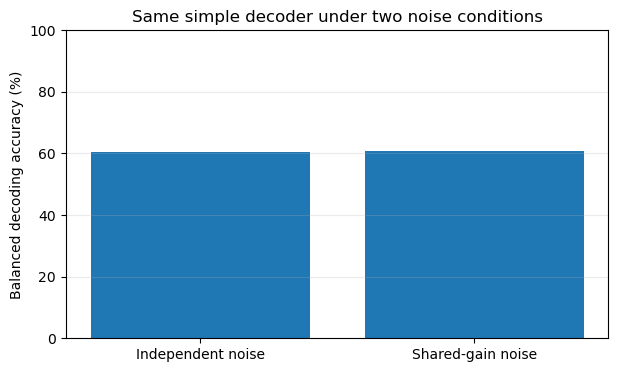

In [49]:
plt.figure(figsize=(7, 4))
plt.bar(["Independent noise", "Shared-gain noise"],
        [100 * acc_ind, 100 * acc_shared])
plt.ylabel("Balanced decoding accuracy (%)")
plt.title("Same simple decoder under two noise conditions")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)
plt.show()

## 11. Explore population size

How does the number of neurons influence the discrimination of nearby visual orientations?

To investigate this, we vary the population size from 1 to 24 neurons. For each population, preferred orientations are distributed between 5° and 35°.

We simulate responses to two candidate orientations (20° and 25°) under two conditions:

- Independent Poisson variability.
- Shared-gain correlated variability.

The same nearest-mean decoder is used for both conditions.

We evaluate balanced decoding accuracy across repeated simulated trials.

**Note:** The preferred-orientation arrangement is regenerated for each population size. Therefore, this comparison explores the combined influence of population size and preferred-orientation sampling, rather than isolating population size as the only changing factor.

In [50]:
def simulate_for_preferences(theta, preferences, n_trials, correlated=False, sigma_shared=0.5):
    lam = population_expected_counts(theta, preferences)

    if not correlated:
        return np.random.poisson(lam, size=(n_trials, len(preferences)))

    z = np.random.normal(0, 1, size=n_trials)
    gain = np.exp(sigma_shared * z - sigma_shared**2 / 2)
    return np.random.poisson(gain[:, None] * lam[None, :])

population_sizes = [1, 3, 6, 12, 24]
n_sweep = 3000
acc_ind_sizes = []
acc_shared_sizes = []

for n_neurons in population_sizes:
    prefs = np.linspace(5, 35, n_neurons)
    decoder = make_nearest_mean_decoder(prefs)

    # Independent-noise populations for both candidate stimuli.
    i20 = simulate_for_preferences(20, prefs, n_sweep, correlated=False)
    i25 = simulate_for_preferences(25, prefs, n_sweep, correlated=False)

    # Shared-gain populations for both candidate stimuli.
    s20 = simulate_for_preferences(20, prefs, n_sweep, correlated=True,
                                   sigma_shared=sigma_shared)
    s25 = simulate_for_preferences(25, prefs, n_sweep, correlated=True,
                                   sigma_shared=sigma_shared)

    acc_ind_sizes.append(balanced_accuracy(i20, i25, decoder))
    acc_shared_sizes.append(balanced_accuracy(s20, s25, decoder))

print("Population sizes:", population_sizes)
print("Independent noise:", np.round(acc_ind_sizes, 3))
print("Shared gain:", np.round(acc_shared_sizes, 3))

Population sizes: [1, 3, 6, 12, 24]
Independent noise: [0.593 0.613 0.658 0.726 0.801]
Shared gain: [0.564 0.599 0.667 0.717 0.78 ]


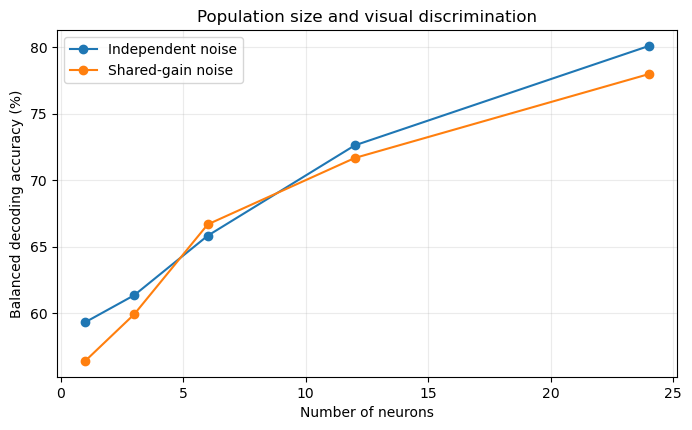

In [59]:
plt.figure(figsize=(8, 4.5))
plt.plot(population_sizes, np.array(acc_ind_sizes) * 100, marker="o",
         label="Independent noise")
plt.plot(population_sizes, np.array(acc_shared_sizes) * 100, marker="o",
         label="Shared-gain noise")
plt.xlabel("Number of neurons")
plt.ylabel("Balanced decoding accuracy (%)")
plt.title("Population size and visual discrimination")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

 ## 12. Summary of Decoding Results

The project links:

1. Visual orientation \(\theta\).
2. Mean tuning curves \(r_i(\theta)\).
3. Expected counts \(\lambda_i(\theta)=r_i(\theta)T\).
4. Poisson spike-count variability.
5. Population coding across neurons.
6. Decoding noisy responses.
7. Accuracy across repeated trials.
8. Shared fluctuations and noise correlations.

### Model limitations

- Gaussian-shaped tuning curves are simplified.
- Poisson variability assumes variance equals mean conditional on rate.
- Shared gain is one simplified mechanism for positive correlations.
- The nearest-mean decoder is not guaranteed to be optimal.
- We test only two candidate orientations.
- Real neural responses can have temporal structure, adaptation, and more complex correlations.
- Results depend on model parameters and simulation randomness.




The following sections extend this analysis by examining Fisher information,
population-level information, and the theoretical limits of orientation
estimation using the Cramér–Rao lower bound.

## 13. Fisher information of a single neuron

Fisher information quantifies how informative a neuron's spike count is about the stimulus orientation. For a Poisson spike count with expected count `lambda(theta)`:

\[
J(\theta)=\frac{[\lambda'(\theta)]^2}{\lambda(\theta)}
\]

Because `lambda(theta) = duration * tuning_rate(theta)`, this can also be written as:

\[
J(\theta)=T\frac{[r'(\theta)]^2}{r(\theta)}
\]

For our Gaussian tuning curve, the derivative is:

\[
r'(\theta)=-A\exp\left[-\frac{(\theta-\theta_p)^2}{2\sigma_\theta^2}\right]
\frac{\theta-\theta_p}{\sigma_\theta^2}
\]

At the exact preferred orientation, the derivative is zero, so this idealized single neuron's Fisher information is zero there. Information is generally greatest on the flanks, where the tuning curve changes most steeply relative to its response variability.


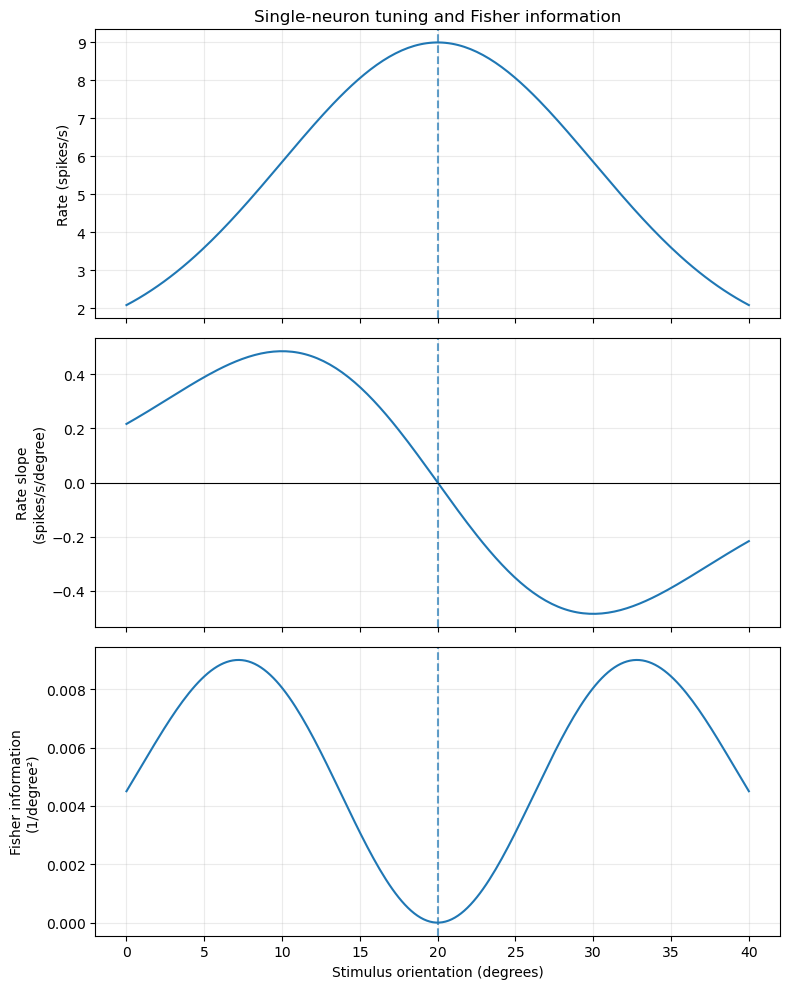

Preferred orientation: 20.0 degrees
Fisher information at preferred orientation: 0.000001 per degree²
Maximum Fisher information: 0.009002 per degree²
Orientation of maximum Fisher information: 7.24 degrees
Fisher information at preferred orientation: 0.00000000 per degree²


In [60]:
# Derivative of the Gaussian tuning curve: dr/dtheta
def tuning_rate_derivative(theta, preferred=theta_pref):
    offset = theta - preferred
    gaussian = np.exp(-(offset**2) / (2 * sigma_theta**2))
    return -A * gaussian * offset / (sigma_theta**2)

# Expected count and its derivative with respect to orientation
rate_curve = tuning_rate(theta_values)
rate_slope = tuning_rate_derivative(theta_values)
lambda_curve = rate_curve * duration
lambda_slope = rate_slope * duration

# Poisson Fisher information: [d lambda / d theta]^2 / lambda
fisher_single = (lambda_slope**2) / lambda_curve

# Plot tuning, sensitivity, and Fisher information
fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

axes[0].plot(theta_values, rate_curve)
axes[0].axvline(theta_pref, linestyle="--", alpha=0.7)
axes[0].set_ylabel("Rate (spikes/s)")
axes[0].set_title("Single-neuron tuning and Fisher information")

axes[1].plot(theta_values, rate_slope)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvline(theta_pref, linestyle="--", alpha=0.7)
axes[1].set_ylabel("Rate slope\n(spikes/s/degree)")

axes[2].plot(theta_values, fisher_single)
axes[2].axvline(theta_pref, linestyle="--", alpha=0.7)
axes[2].set_xlabel("Stimulus orientation (degrees)")
axes[2].set_ylabel("Fisher information\n(1/degree²)")
for ax in axes:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

peak_index = np.argmax(fisher_single)
print(f"Preferred orientation: {theta_pref:.1f} degrees")
print(f"Fisher information at preferred orientation: "
      f"{fisher_single[np.argmin(np.abs(theta_values-theta_pref))]:.6f} per degree²")
print(f"Maximum Fisher information: {fisher_single[peak_index]:.6f} per degree²")
print(f"Orientation of maximum Fisher information: {theta_values[peak_index]:.2f} degrees")

fisher_at_preferred = (
    (duration * tuning_rate_derivative(theta_pref))**2
    / (duration * tuning_rate(theta_pref))
)

print(
    "Fisher information at preferred orientation:",
    f"{fisher_at_preferred:.8f} per degree²"
)

### Interpretation

The tuning curve peaks at the neuron's preferred orientation, but its slope is zero at that peak. Consequently, a small change in orientation near the peak produces only a second-order change in the mean response, and the local Fisher information is zero for this symmetric tuning curve.

On either side of the peak, the slope becomes nonzero. The neuron can then provide information about small orientation changes. The two flanks can both be informative, although the exact information profile depends on baseline rate, amplitude, tuning width, and observation duration.

**Units:** because orientation is measured in degrees, Fisher information has units of inverse degrees squared. Doubling the observation duration doubles the Fisher information for this Poisson model.


## 14. Population Fisher Information

A single neuron provides information about stimulus orientation through changes in its firing rate. However, visual information is represented by populations of neurons with different orientation preferences.

For conditionally independent Poisson neurons, the Fisher information contributed by the population is the sum of the information from individual neurons:

\[
J_{\mathrm{population}}(\theta)
=
\sum_{i=1}^{N}
\frac{[\lambda_i'(\theta)]^2}{\lambda_i(\theta)}
\]

where:

- \(N\) = number of neurons.
- \(\lambda_i(\theta)\) = expected spike count of neuron \(i\).
- \(\lambda_i'(\theta)\) = derivative of expected spike count with respect to orientation.

This allows us to investigate how a population of differently tuned neurons collectively represents visual orientation.

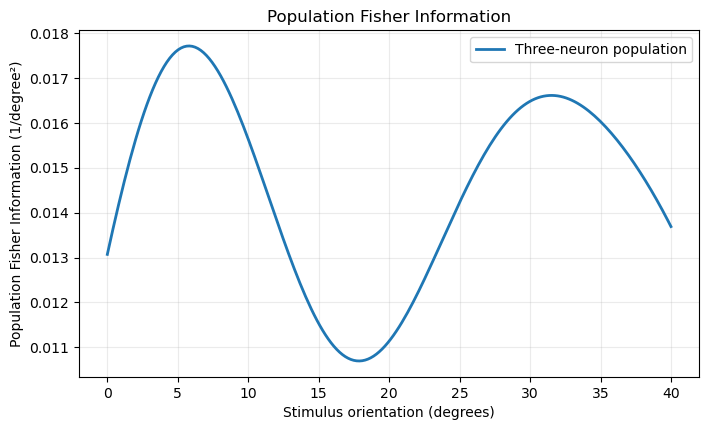

Population Fisher Information at 20 degrees: 0.01113826227167223


In [53]:
# Calculate population Fisher information
def population_fisher_information(theta, preferences):

    total_information = 0

    for pref in preferences:

        # Mean firing rate
        rate = tuning_rate(theta, preferred=pref)

        # Derivative of firing rate
        rate_derivative = tuning_rate_derivative(
            theta, preferred=pref
        )

        # Expected spike count and its derivative
        lam = rate * duration
        lam_derivative = rate_derivative * duration

        # Individual neuron's Fisher information
        neuron_information = (lam_derivative**2) / lam

        total_information += neuron_information

    return total_information


# Calculate information across orientations
population_fisher = np.array([
    population_fisher_information(theta, preferred_orientations)
    for theta in theta_values
])

plt.figure(figsize=(8, 4.5))

plt.plot(
    theta_values,
    population_fisher,
    linewidth=2,
    label="Three-neuron population"
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Population Fisher Information (1/degree²)")
plt.title("Population Fisher Information")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(
    "Population Fisher Information at 20 degrees:",
    population_fisher_information(20, preferred_orientations)
)

## 15. Cramér–Rao Lower Bound (CRLB)

Fisher information tells us how much information neural responses contain about a stimulus. The Cramér–Rao lower bound connects this information to the precision of stimulus estimation.

For an unbiased estimator:

\[
\mathrm{Var}(\hat{\theta}) \geq \frac{1}{J(\theta)}
\]

The corresponding standard deviation bound is:

\[
\mathrm{SD}(\hat{\theta}) \geq \frac{1}{\sqrt{J(\theta)}}
\]

A higher Fisher information corresponds to a lower theoretical bound on estimation variability.

We use the population Fisher information calculated in the previous section to estimate the theoretical precision limit for orientation estimation.

The CRLB is a theoretical lower bound, not the actual error of a particular neural decoder.

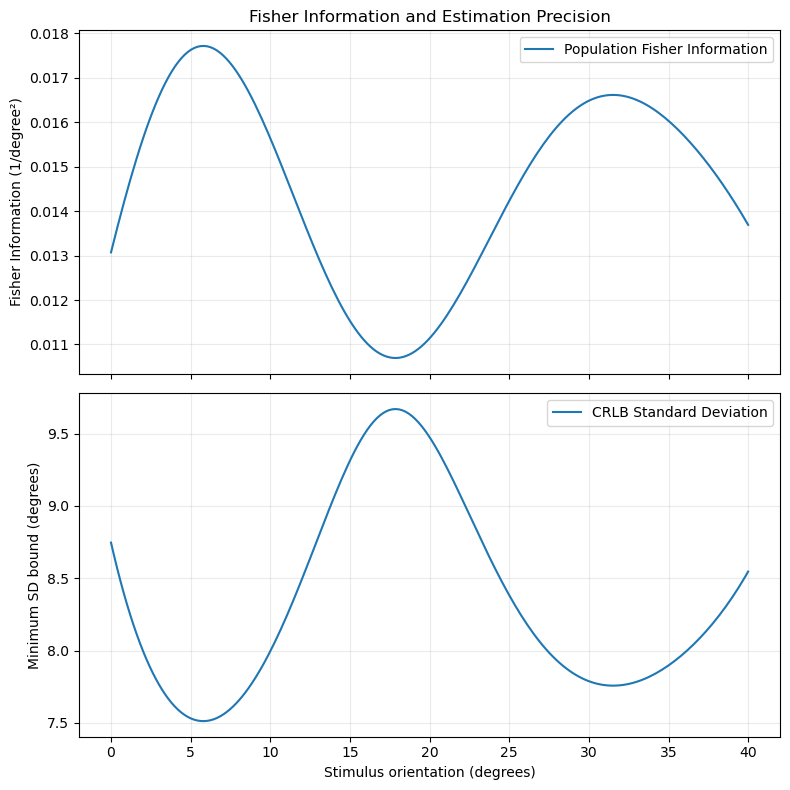

Population Fisher Information: 0.01113826227167223
CRLB variance: 89.78061169768687
CRLB standard deviation: 9.475263146619563


In [54]:
# Calculate Cramer-Rao Lower Bound

crlb_variance = 1 / population_fisher

crlb_sd = 1 / np.sqrt(population_fisher)

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# Fisher information
axes[0].plot(
    theta_values,
    population_fisher,
    label="Population Fisher Information"
)

axes[0].set_ylabel("Fisher Information (1/degree²)")
axes[0].set_title("Fisher Information and Estimation Precision")
axes[0].legend()
axes[0].grid(alpha=0.25)

# CRLB
axes[1].plot(
    theta_values,
    crlb_sd,
    label="CRLB Standard Deviation"
)

axes[1].set_xlabel("Stimulus orientation (degrees)")
axes[1].set_ylabel("Minimum SD bound (degrees)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Display values at 20 degrees
J_20 = population_fisher_information(
    20, preferred_orientations
)

print("Population Fisher Information:", J_20)

print("CRLB variance:", 1 / J_20)

print("CRLB standard deviation:", 1 / np.sqrt(J_20))

## 16. Effect of Population Size on Fisher Information

Does increasing the number of neurons improve the precision of visual orientation representation?

To investigate this, we vary the population size while distributing neuronal preferred orientations across the stimulus range.

For each population size, we calculate:

1. Population Fisher information.
2. Cramér–Rao lower bound.
3. The relationship between population size and theoretical estimation precision.

This allows us to examine how population coding contributes to sensory information.

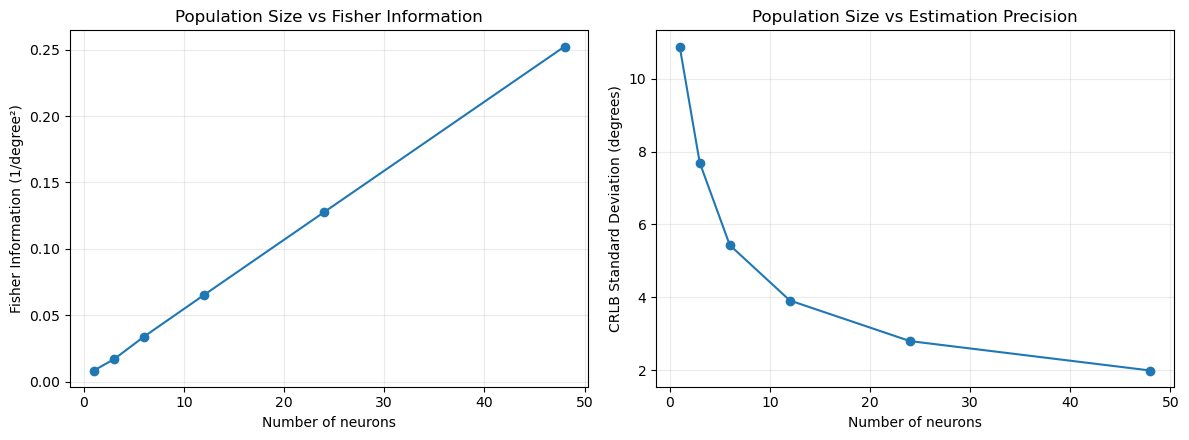

,Number of neurons,Fisher Information,CRLB Standard Deviation
0,1,0.008438,10.886005
1,3,0.016877,7.697568
2,6,0.033871,5.433561
3,12,0.065300,3.913291
4,24,0.127697,2.798402
5,48,0.252307,1.990835


In [55]:
# Investigate the effect of population size

population_sizes_fi = [1, 3, 6, 12, 24, 48]

fisher_by_size = []
crlb_by_size = []

test_orientation = 20

for n in population_sizes_fi:

    # Distribute preferred orientations across 5 to 35 degrees
    preferences = np.linspace(5, 35, n)

    # Calculate population Fisher information
    J = population_fisher_information(
        test_orientation, preferences
    )

    # Calculate CRLB standard deviation
    bound = 1 / np.sqrt(J)

    fisher_by_size.append(J)
    crlb_by_size.append(bound)


# Plot results
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    population_sizes_fi,
    fisher_by_size,
    marker="o"
)

axes[0].set_xlabel("Number of neurons")
axes[0].set_ylabel("Fisher Information (1/degree²)")
axes[0].set_title("Population Size vs Fisher Information")
axes[0].grid(alpha=0.25)


axes[1].plot(
    population_sizes_fi,
    crlb_by_size,
    marker="o"
)

axes[1].set_xlabel("Number of neurons")
axes[1].set_ylabel("CRLB Standard Deviation (degrees)")
axes[1].set_title("Population Size vs Estimation Precision")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


# Display numerical results
population_fi_results = pd.DataFrame({
    "Number of neurons": population_sizes_fi,
    "Fisher Information": fisher_by_size,
    "CRLB Standard Deviation": crlb_by_size
})

display(population_fi_results)

## 17. Population Fisher Information under Correlated Noise

Neurons can exhibit correlated trial-to-trial variability due to shared inputs and network activity.

In the independent Poisson model, population Fisher information is the sum of individual neuronal contributions.

However, when neural responses are correlated, information depends on the population covariance structure.

For our shared-gain model:

N_i | g, theta ~ Poisson(g * lambda_i(theta))

\[
\Sigma(\theta)=\operatorname{diag}(\lambda)+v\lambda\lambda^T
\]

where g is a shared, positive, trial-specific gain.

The covariance matrix is:

Sigma(theta) = diag(lambda) + v * lambda * lambda.T

where:

v = exp(sigma_shared²) - 1

To investigate its effect on population information, we use a Gaussian approximation to the shared-gain population response.

For a Gaussian distribution with stimulus-dependent mean and covariance:

J(theta) = mu'(theta).T Sigma^(-1) mu'(theta)
           + 0.5 * trace[
               Sigma^(-1) Sigma'
               Sigma^(-1) Sigma'
             ]

This includes information carried by changes in both the mean response and the covariance structure.

This is a Gaussian moment approximation, not the exact Fisher information of the underlying Poisson-lognormal mixture.

In [56]:
# Covariance matrix for the shared-gain population

def shared_gain_covariance(theta, preferences, sigma_shared):

    # Expected spike counts
    rates = r_base + A * np.exp(
        -((theta - preferences)**2) / (2 * sigma_theta**2)
    )

    lam = rates * duration

    # Variance of the shared lognormal gain
    gain_variance = np.exp(sigma_shared**2) - 1

    # Population covariance
    covariance = (
        np.diag(lam)
        + gain_variance * np.outer(lam, lam)
    )

    return covariance


# Gaussian approximation to population Fisher information

def correlated_population_fisher(
    theta,
    preferences,
    sigma_shared,
    epsilon=1e-3
):

    # Mean response
    rates = r_base + A * np.exp(
        -((theta - preferences)**2) / (2 * sigma_theta**2)
    )

    mean_counts = rates * duration

    # Derivative of the mean response
    rate_derivative = (
        -A
        * np.exp(
            -((theta - preferences)**2) / (2 * sigma_theta**2)
        )
        * (theta - preferences)
        / sigma_theta**2
    )

    mean_derivative = rate_derivative * duration

    # Covariance matrix
    covariance = shared_gain_covariance(
        theta, preferences, sigma_shared
    )

    # Numerical derivative of covariance
    covariance_plus = shared_gain_covariance(
        theta + epsilon, preferences, sigma_shared
    )

    covariance_minus = shared_gain_covariance(
        theta - epsilon, preferences, sigma_shared
    )

    covariance_derivative = (
        covariance_plus - covariance_minus
    ) / (2 * epsilon)

    # Mean-dependent Fisher information
    solved_mean = np.linalg.solve(
        covariance, mean_derivative
    )

    mean_information = mean_derivative @ solved_mean

    # Covariance-dependent Fisher information
    solved_covariance_derivative = np.linalg.solve(
        covariance, covariance_derivative
    )

    covariance_information = 0.5 * np.trace(
        solved_covariance_derivative
        @ solved_covariance_derivative
    )

    return mean_information + covariance_information

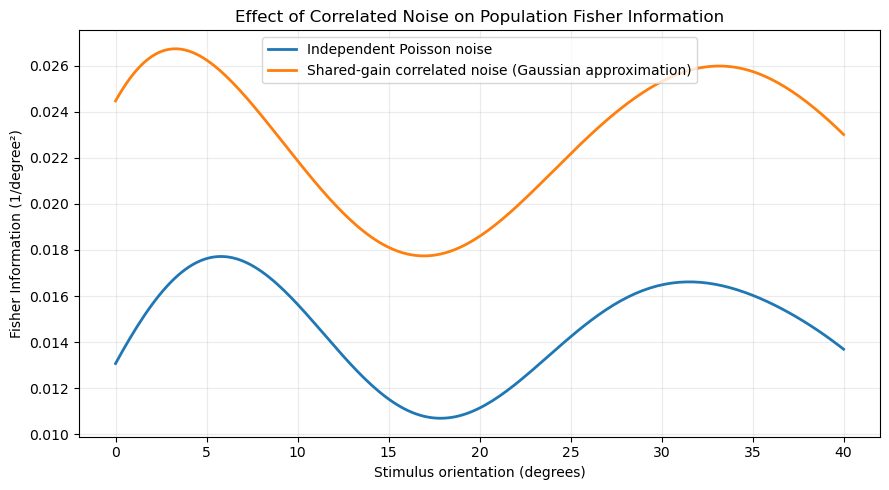

In [57]:
# Compare independent and correlated population information

sigma_shared = 0.5

independent_fisher = np.array([
    population_fisher_information(
        theta, preferred_orientations
    )
    for theta in theta_values
])

correlated_fisher = np.array([
    correlated_population_fisher(
        theta,
        preferred_orientations,
        sigma_shared
    )
    for theta in theta_values
])


plt.figure(figsize=(9, 5))

plt.plot(
    theta_values,
    independent_fisher,
    label="Independent Poisson noise",
    linewidth=2
)

plt.plot(
    theta_values,
    correlated_fisher,
    label="Shared-gain correlated noise (Gaussian approximation)",
    linewidth=2
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Fisher Information (1/degree²)")

plt.title(
    "Effect of Correlated Noise on Population Fisher Information"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [58]:
# Compare theoretical precision bounds at 20 degrees

J_independent = population_fisher_information(
    20, preferred_orientations
)

J_correlated = correlated_population_fisher(
    20, preferred_orientations, sigma_shared
)

crlb_independent = 1 / np.sqrt(J_independent)
crlb_correlated = 1 / np.sqrt(J_correlated)

print("Independent Poisson model")
print("Fisher Information:", J_independent)
print("CRLB standard deviation:", crlb_independent)

print("\nShared-gain Gaussian approximation")
print("Fisher Information:", J_correlated)
print("CRLB standard deviation:", crlb_correlated)

Independent Poisson model
Fisher Information: 0.01113826227167223
CRLB standard deviation: 9.475263146619563

Shared-gain Gaussian approximation
Fisher Information: 0.018592631873506717
CRLB standard deviation: 7.333808487119069


## 18. Overall Interpretation and Conclusions

This project investigates how neural variability influences the precision of visual orientation representation.

The model connects several levels of sensory neuroscience:

1. Orientation-selective neuronal tuning.
2. Poisson spike-count variability.
3. Population coding across differently tuned neurons.
4. Maximum-likelihood decoding of visual stimuli.
5. Shared fluctuations and correlated neural responses.
6. Single-neuron and population Fisher information.
7. Cramér–Rao lower bounds on orientation-estimation precision.

### Key questions explored

- How does neuronal tuning influence sensory information?
- Why can a population of differently tuned neurons encode orientation more effectively than an individual neuron?
- How does shared variability influence population information?
- How does Fisher information relate to the theoretical precision of stimulus estimation?

### Important limitations

- The model uses simplified Gaussian orientation tuning curves.
- Neural responses are modelled using Poisson spike counts.
- Shared gain is a simplified mechanism for generating positive correlations.
- The correlated population Fisher information uses a Gaussian moment approximation.
- The Cramér–Rao lower bound describes theoretical estimation precision, not actual decoding accuracy.
- The model does not include temporal neural dynamics or realistic visual cortical circuitry.
- The simulation does not use experimental neural recordings or human behavioural data.

### Scientific significance

The project provides a computational framework for exploring how neural population activity, response variability and noise correlations influence the representation of sensory information.

It connects neuronal response properties with population-level information and the theoretical limits of perceptual precision.